# Day 029 | SciPy — Signal Processing (FFT, Filtering)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials

**Author:** Ripon Chandra Malo  
**Date:** May 16, 2026

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| **Butterworth Filter** | Zero-phase low/band-pass filter | Remove high-freq noise from accelerometer data |
| **FFT** | Decompose signal into frequency components | Find dominant frequencies in ground motion |
| **Welch PSD** | Smoother power spectral density estimate | Characterise site amplification peaks |
| **find_peaks** | Locate dominant spectral peaks | Identify fundamental site period Ts |
| **Spectrogram** | Time-frequency heatmap | Track energy evolution during earthquake |
| **Arias Intensity** | Cumulative energy measure Ia (m/s) | Correlate to liquefaction triggering |
| **D5-95** | Significant duration of shaking | Input for non-linear site response models |

---

## Our Geotechnical Problem

A strong-motion accelerometer at a site records ground acceleration during a local M5.5 earthquake. The raw record is contaminated with high-frequency instrument noise and a low-frequency baseline drift. We need to:
1. Clean the signal (filter)
2. Identify dominant frequency content (FFT, Welch, find_peaks)
3. Track how energy evolves in time (spectrogram)
4. Compute engineering intensity measures (Arias Intensity, D5-95)

These steps are the preprocessing pipeline before feeding earthquake records into ML models for site amplification, liquefaction potential, or structural damage prediction.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, fft
from scipy.signal import butter, filtfilt, welch, find_peaks, spectrogram

np.random.seed(42)
print('Libraries loaded.')
print('scipy version:', __import__('scipy').__version__)

Libraries loaded.
scipy version: 1.17.1


## Part 1: Synthetic Ground Acceleration Record

Sampling rate     : 100 Hz
Duration          : 10.0 s  →  1000 samples
Nyquist frequency : 50.0 Hz
Peak ground accel : 0.3683 g


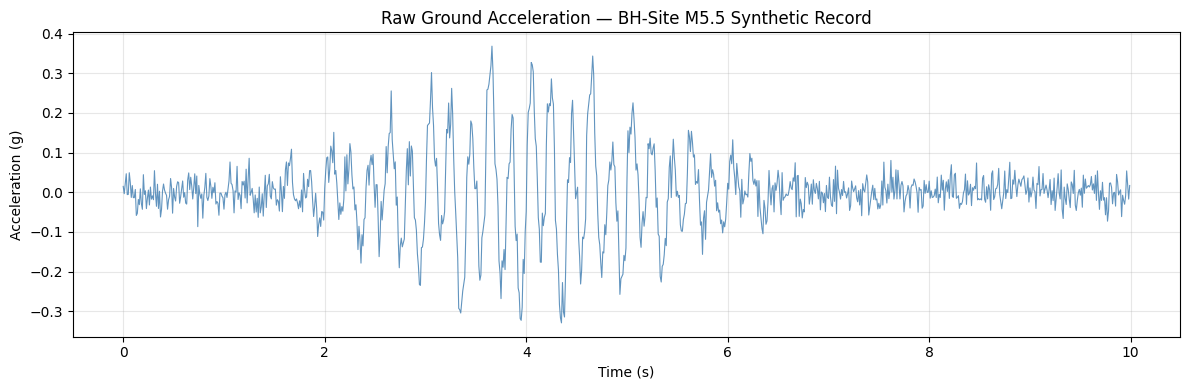

In [2]:
# ─────────────────────────────────────────────────────
# GENERATE SYNTHETIC EARTHQUAKE ACCELERATION RECORD
# Signal = 2 Hz (S-wave body wave) +
#          5 Hz (site resonance)    +
#         20 Hz (instrument noise)  +
#          random broadband noise
# ─────────────────────────────────────────────────────

fs     = 100          # sampling rate (Hz) — typical strong-motion recorder
T      = 10.0         # duration (s)
N      = int(fs * T)  # number of samples
t      = np.linspace(0, T, N, endpoint=False)

# Envelope: taper to simulate earthquake build-up and decay
envelope = np.exp(-((t - 4.0)**2) / 3.0)

# Three sinusoidal components (peak ground acceleration in g)
a_2hz  = 0.10 * np.sin(2 * np.pi * 2  * t) * envelope   # body-wave content
a_5hz  = 0.25 * np.sin(2 * np.pi * 5  * t) * envelope   # site resonance
a_20hz = 0.05 * np.sin(2 * np.pi * 20 * t) * envelope   # noise band

# Broadband random noise
noise  = 0.03 * np.random.randn(N)

# Raw acceleration record (units: g)
a_raw  = a_2hz + a_5hz + a_20hz + noise

print(f'Sampling rate     : {fs} Hz')
print(f'Duration          : {T} s  →  {N} samples')
print(f'Nyquist frequency : {fs/2} Hz')
print(f'Peak ground accel : {np.max(np.abs(a_raw)):.4f} g')

plt.figure(figsize=(12, 4))
plt.plot(t, a_raw, lw=0.8, color='steelblue', alpha=0.85)
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (g)')
plt.title('Raw Ground Acceleration — BH-Site M5.5 Synthetic Record')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Part 2: Low-Pass Butterworth Filter — Remove Instrument Noise

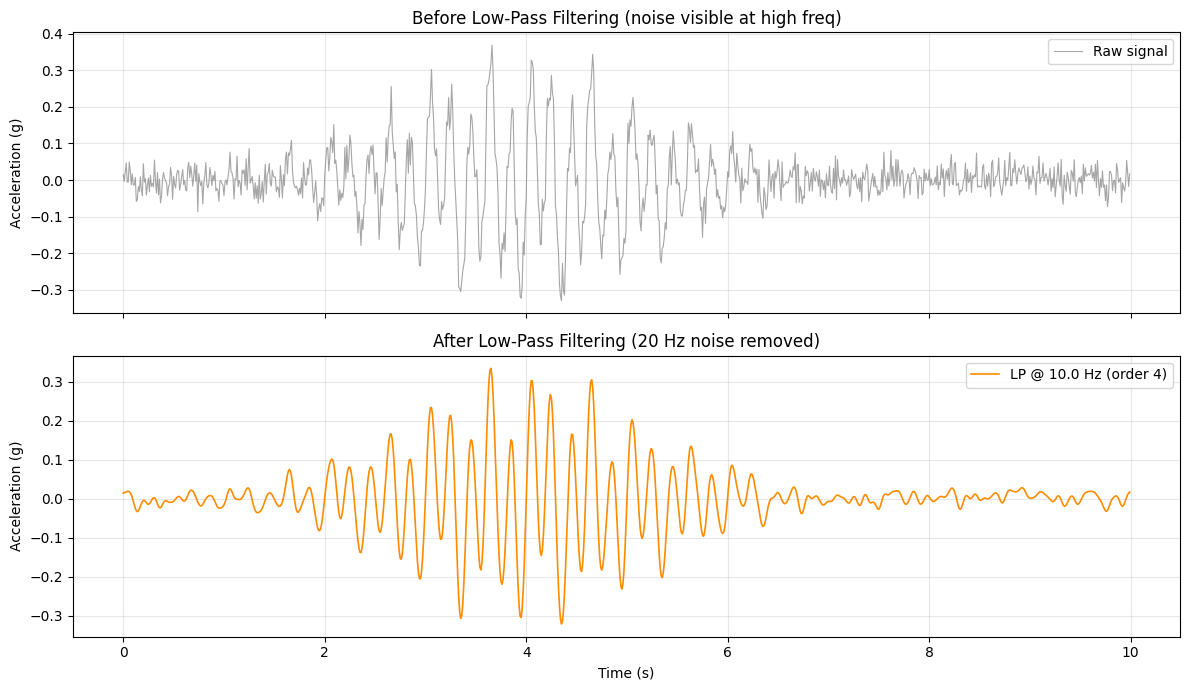

Signal std (raw)      : 0.09356 g
Signal std (filtered) : 0.08819 g
Noise energy reduced  : 5.7 %


In [3]:
# ─────────────────────────────────────────────────────
# BUTTERWORTH LOW-PASS FILTER  @  10 Hz
# filtfilt: zero-phase (no time shift) — mandatory
# for engineering intensity measure calculations
# ─────────────────────────────────────────────────────

fc_lp    = 10.0    # low-pass corner frequency (Hz)
order_lp = 4       # filter order

# Design the filter
b_lp, a_lp = butter(order_lp, fc_lp, btype='low', fs=fs)

# Apply zero-phase filter
a_lp_filtered = filtfilt(b_lp, a_lp, a_raw)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t, a_raw, lw=0.8, color='gray', alpha=0.7, label='Raw signal')
axes[0].set_ylabel('Acceleration (g)')
axes[0].set_title('Before Low-Pass Filtering (noise visible at high freq)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(t, a_lp_filtered, lw=1.2, color='darkorange', label=f'LP @ {fc_lp} Hz (order {order_lp})')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Acceleration (g)')
axes[1].set_title('After Low-Pass Filtering (20 Hz noise removed)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

noise_removed_pct = (1 - np.std(a_lp_filtered) / np.std(a_raw)) * 100
print(f'Signal std (raw)      : {np.std(a_raw):.5f} g')
print(f'Signal std (filtered) : {np.std(a_lp_filtered):.5f} g')
print(f'Noise energy reduced  : {noise_removed_pct:.1f} %')

## Part 3: Band-Pass Filter — Isolate Earthquake Content (1–8 Hz)

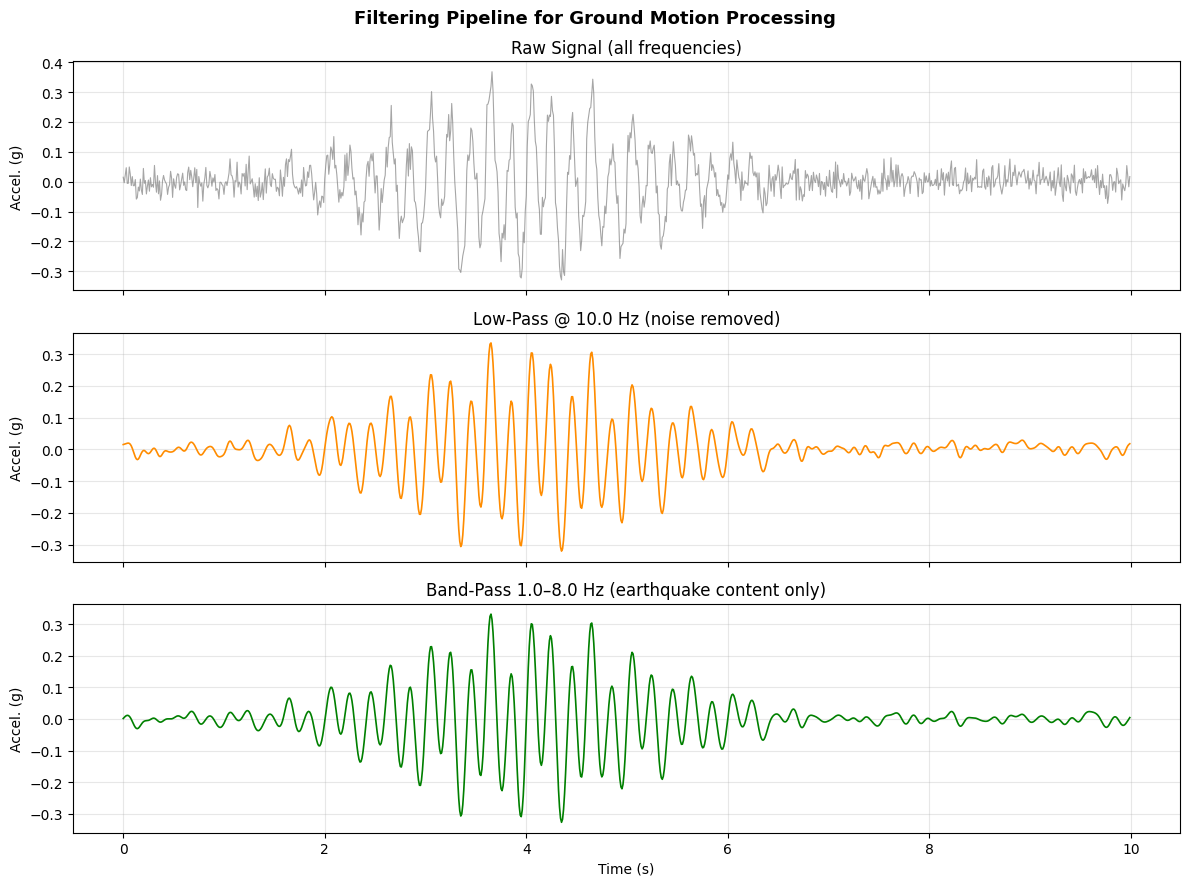

PGA raw           : 0.3683 g
PGA low-pass      : 0.3349 g
PGA band-pass     : 0.3318 g


In [4]:
# ─────────────────────────────────────────────────────
# BAND-PASS FILTER: 1 – 8 Hz
# Passes the earthquake energy window; removes both
# low-freq baseline drift and high-freq noise
# ─────────────────────────────────────────────────────

fc_low  = 1.0    # lower corner (Hz)
fc_high = 8.0    # upper corner (Hz)
order_bp = 4

b_bp, a_bp = butter(order_bp, [fc_low, fc_high], btype='band', fs=fs)
a_bp_filtered = filtfilt(b_bp, a_bp, a_raw)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(t, a_raw, lw=0.8, color='gray', alpha=0.7)
axes[0].set_title('Raw Signal (all frequencies)')
axes[0].set_ylabel('Accel. (g)'); axes[0].grid(True, alpha=0.3)

axes[1].plot(t, a_lp_filtered, color='darkorange', lw=1.2)
axes[1].set_title(f'Low-Pass @ {fc_lp} Hz (noise removed)')
axes[1].set_ylabel('Accel. (g)'); axes[1].grid(True, alpha=0.3)

axes[2].plot(t, a_bp_filtered, color='green', lw=1.2)
axes[2].set_title(f'Band-Pass {fc_low}–{fc_high} Hz (earthquake content only)')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Accel. (g)'); axes[2].grid(True, alpha=0.3)

plt.suptitle('Filtering Pipeline for Ground Motion Processing', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'PGA raw           : {np.max(np.abs(a_raw)):.4f} g')
print(f'PGA low-pass      : {np.max(np.abs(a_lp_filtered)):.4f} g')
print(f'PGA band-pass     : {np.max(np.abs(a_bp_filtered)):.4f} g')

## Part 4: FFT — Amplitude Spectrum

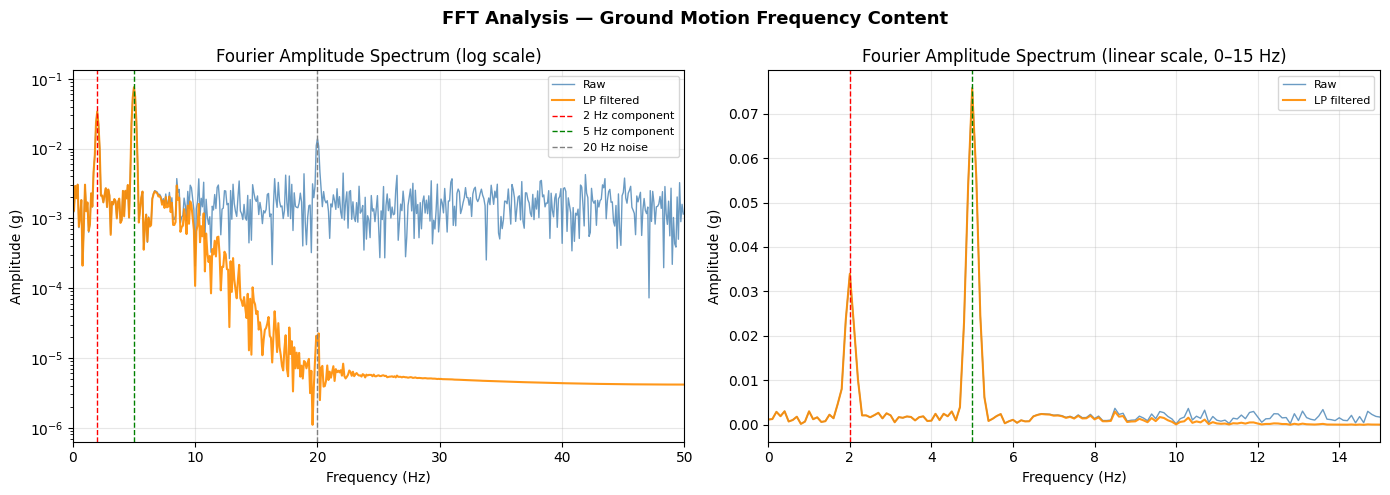

Top 5 amplitude peaks (raw signal):
  f =  5.00 Hz  |  amplitude = 0.0759 g
  f =  5.10 Hz  |  amplitude = 0.0561 g
  f =  4.90 Hz  |  amplitude = 0.0537 g
  f =  2.00 Hz  |  amplitude = 0.0340 g
  f =  5.20 Hz  |  amplitude = 0.0244 g


In [5]:
# ─────────────────────────────────────────────────────
# scipy.fft.fft + np.fft.fftfreq
# One-sided amplitude spectrum (0 to Nyquist)
# ─────────────────────────────────────────────────────

# FFT of the raw signal
A_raw  = fft.fft(a_raw)
freqs  = np.fft.fftfreq(N, d=1/fs)   # frequency axis (Hz)

# Keep only positive frequencies (one-sided spectrum)
pos_mask  = freqs >= 0
freqs_pos = freqs[pos_mask]
amp_raw   = (2 / N) * np.abs(A_raw[pos_mask])   # normalised amplitude

# FFT of filtered signal for comparison
A_lp   = fft.fft(a_lp_filtered)
amp_lp = (2 / N) * np.abs(A_lp[pos_mask])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(freqs_pos, amp_raw, color='steelblue', lw=1.0, alpha=0.8, label='Raw')
axes[0].semilogy(freqs_pos, amp_lp,  color='darkorange', lw=1.5, alpha=0.9, label='LP filtered')
axes[0].axvline(2,  color='red',   ls='--', lw=1, label='2 Hz component')
axes[0].axvline(5,  color='green', ls='--', lw=1, label='5 Hz component')
axes[0].axvline(20, color='gray',  ls='--', lw=1, label='20 Hz noise')
axes[0].set_xlabel('Frequency (Hz)'); axes[0].set_ylabel('Amplitude (g)')
axes[0].set_title('Fourier Amplitude Spectrum (log scale)')
axes[0].set_xlim(0, 50); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(freqs_pos, amp_raw, color='steelblue', lw=1.0, alpha=0.8, label='Raw')
axes[1].plot(freqs_pos, amp_lp,  color='darkorange', lw=1.5, alpha=0.9, label='LP filtered')
axes[1].axvline(2, color='red',   ls='--', lw=1)
axes[1].axvline(5, color='green', ls='--', lw=1)
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('Amplitude (g)')
axes[1].set_title('Fourier Amplitude Spectrum (linear scale, 0–15 Hz)')
axes[1].set_xlim(0, 15); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.suptitle('FFT Analysis — Ground Motion Frequency Content', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Find the two dominant peaks
peak_idx = np.argsort(amp_raw)[-5:][::-1]
print('Top 5 amplitude peaks (raw signal):')
for i in peak_idx:
    print(f'  f = {freqs_pos[i]:5.2f} Hz  |  amplitude = {amp_raw[i]:.4f} g')

## Part 5: Welch PSD — Power Spectral Density

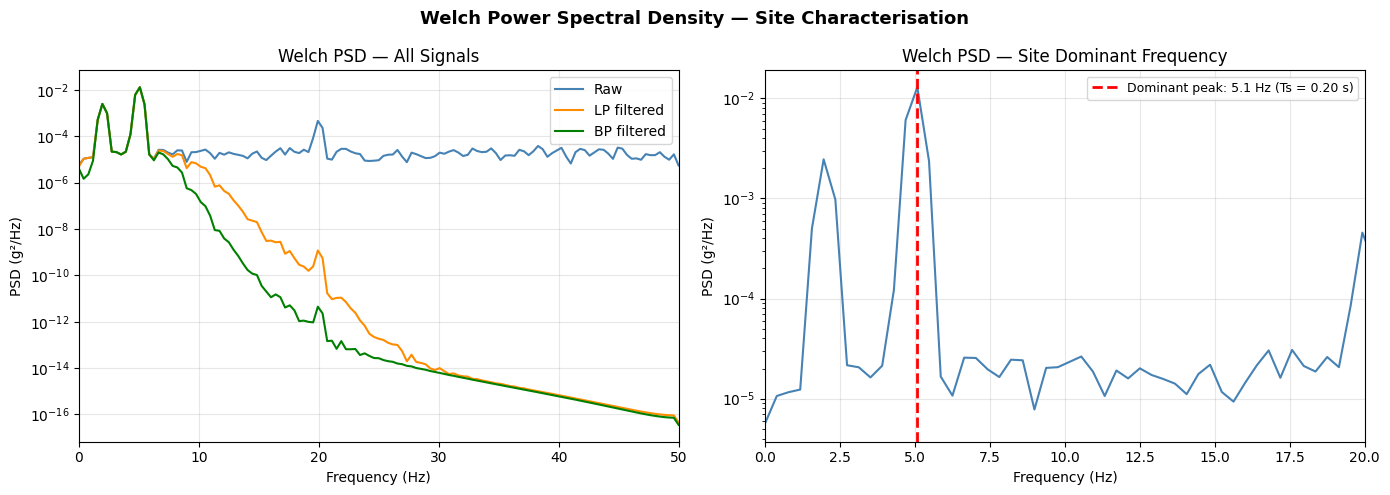

Dominant frequency (Welch): 5.08 Hz
Site dominant period Ts   : 0.197 s
Welch nperseg=256 → freq resolution: 0.391 Hz/bin


In [6]:
# ─────────────────────────────────────────────────────
# scipy.signal.welch: Welch's method for PSD
# Averages periodograms of overlapping windows →
# much smoother than raw FFT²; better for identifying
# site dominant period from noisy records
# ─────────────────────────────────────────────────────

f_welch, psd_raw = welch(a_raw, fs=fs, nperseg=256, noverlap=128, window='hann')
_, psd_lp        = welch(a_lp_filtered, fs=fs, nperseg=256, noverlap=128, window='hann')
_, psd_bp        = welch(a_bp_filtered, fs=fs, nperseg=256, noverlap=128, window='hann')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(f_welch, psd_raw, color='steelblue', lw=1.5, label='Raw')
axes[0].semilogy(f_welch, psd_lp,  color='darkorange', lw=1.5, label='LP filtered')
axes[0].semilogy(f_welch, psd_bp,  color='green',      lw=1.5, label='BP filtered')
axes[0].set_xlabel('Frequency (Hz)'); axes[0].set_ylabel('PSD (g²/Hz)')
axes[0].set_title('Welch PSD — All Signals')
axes[0].set_xlim(0, 50); axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Site H/V concept: annotate the dominant peak
dominant_f = f_welch[np.argmax(psd_raw)]
axes[1].semilogy(f_welch, psd_raw, color='steelblue', lw=1.5)
axes[1].axvline(dominant_f, color='red', ls='--', lw=2,
                label=f'Dominant peak: {dominant_f:.1f} Hz (Ts = {1/dominant_f:.2f} s)')
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('PSD (g²/Hz)')
axes[1].set_title('Welch PSD — Site Dominant Frequency')
axes[1].set_xlim(0, 20); axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.suptitle('Welch Power Spectral Density — Site Characterisation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Dominant frequency (Welch): {dominant_f:.2f} Hz')
print(f'Site dominant period Ts   : {1/dominant_f:.3f} s')
print(f'Welch nperseg=256 → freq resolution: {fs/256:.3f} Hz/bin')

## Part 6: find_peaks — Dominant Spectral Peaks

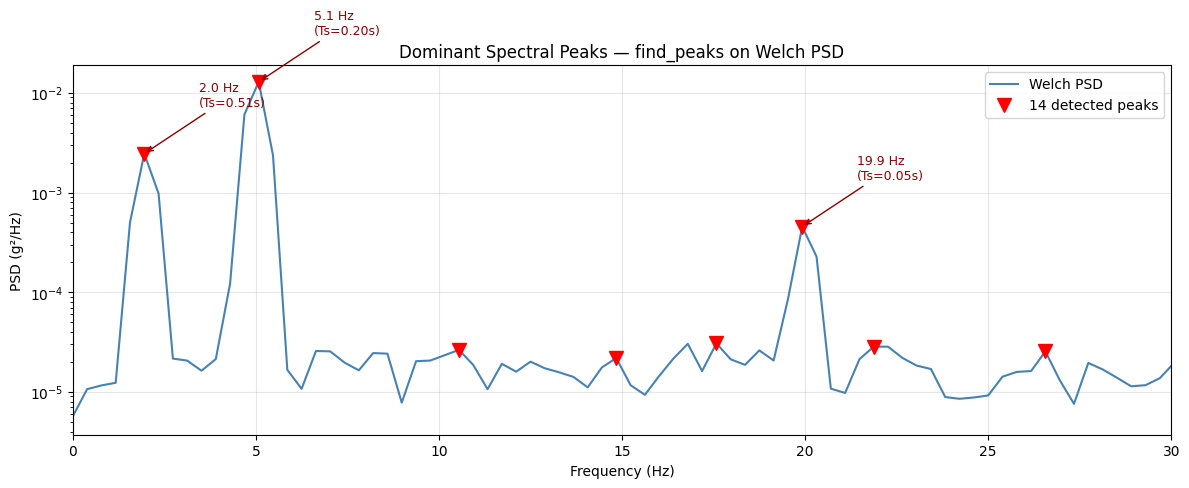

Top 3 dominant frequencies in the ground motion record:
  Rank 1: f = 5.08 Hz  |  Ts = 0.197 s  |  PSD = 1.29e-02 g²/Hz
  Rank 2: f = 1.95 Hz  |  Ts = 0.512 s  |  PSD = 2.46e-03 g²/Hz
  Rank 3: f = 19.92 Hz  |  Ts = 0.050 s  |  PSD = 4.56e-04 g²/Hz


In [7]:
# ─────────────────────────────────────────────────────
# scipy.signal.find_peaks on the Welch PSD
# height: minimum PSD threshold
# distance: minimum separation between peaks (bins)
# prominence: how much a peak stands above its neighbours
# ─────────────────────────────────────────────────────

# Work in linear scale for find_peaks (log would distort prominence)
peaks_idx, peak_props = find_peaks(
    psd_raw,
    height=1e-5,       # minimum PSD value (g²/Hz)
    distance=5,        # at least 5 bins apart
    prominence=1e-5    # must stand out from baseline
)

peaks_f   = f_welch[peaks_idx]
peaks_psd = psd_raw[peaks_idx]

# Sort by PSD height
sort_idx  = np.argsort(peaks_psd)[::-1]
peaks_f_sorted   = peaks_f[sort_idx]
peaks_psd_sorted = peaks_psd[sort_idx]

plt.figure(figsize=(12, 5))
plt.semilogy(f_welch, psd_raw, color='steelblue', lw=1.5, label='Welch PSD')
plt.semilogy(peaks_f, peaks_psd, 'rv', ms=10, label=f'{len(peaks_f)} detected peaks')
for i, (pf, pp) in enumerate(zip(peaks_f_sorted[:3], peaks_psd_sorted[:3])):
    plt.annotate(f'{pf:.1f} Hz\n(Ts={1/pf:.2f}s)',
                 xy=(pf, pp), xytext=(pf + 1.5, pp * 3),
                 fontsize=9, color='darkred',
                 arrowprops=dict(arrowstyle='->', color='darkred'))
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (g²/Hz)')
plt.title('Dominant Spectral Peaks — find_peaks on Welch PSD')
plt.xlim(0, 30)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Top 3 dominant frequencies in the ground motion record:')
for i, (pf, pp) in enumerate(zip(peaks_f_sorted[:3], peaks_psd_sorted[:3]), 1):
    print(f'  Rank {i}: f = {pf:.2f} Hz  |  Ts = {1/pf:.3f} s  |  PSD = {pp:.2e} g²/Hz')

## Part 7: Spectrogram — Time-Frequency Energy Map

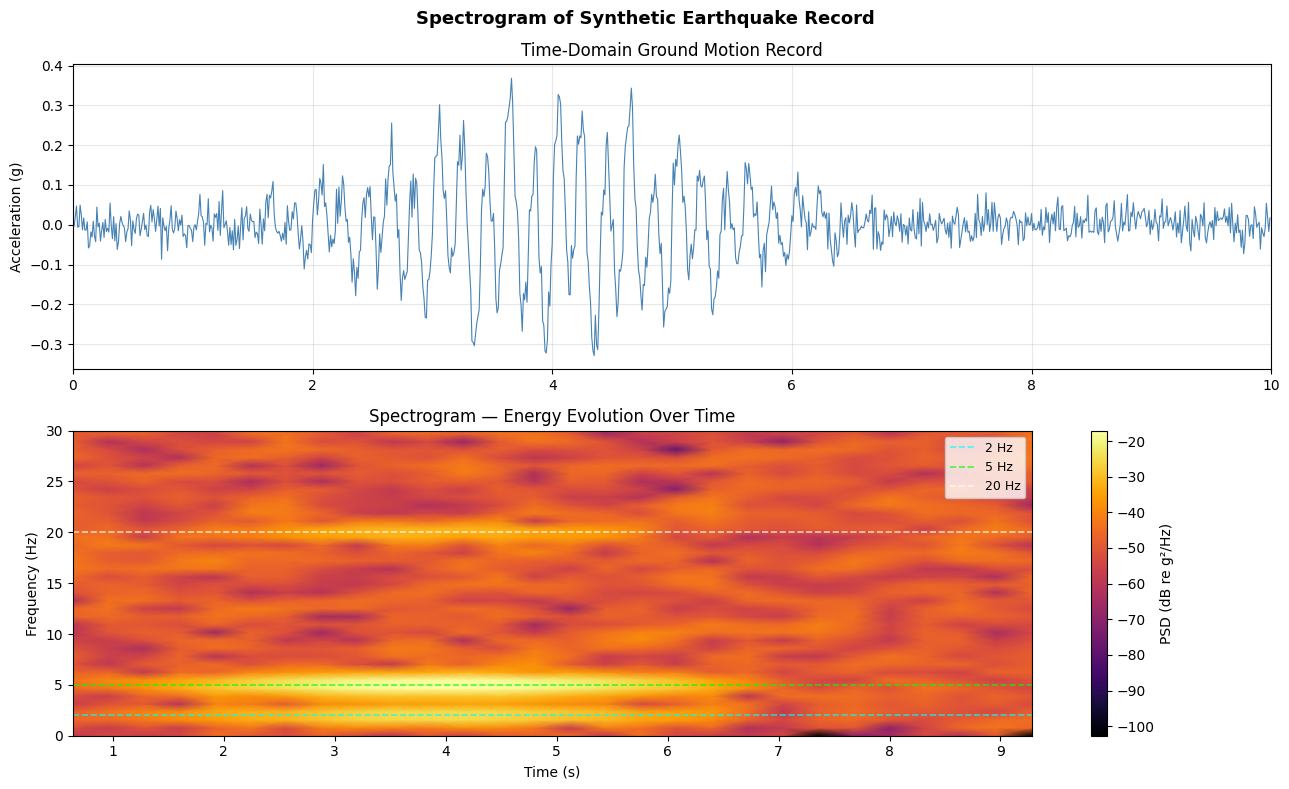

Spectrogram time bins  : 28
Spectrogram freq bins  : 65
Time resolution        : 0.320 s/bin
Frequency resolution   : 0.781 Hz/bin


In [8]:
# ─────────────────────────────────────────────────────
# scipy.signal.spectrogram: short-time Fourier transform
# Shows HOW frequency content changes through time —
# critical for non-stationary earthquake signals
# ─────────────────────────────────────────────────────

f_spec, t_spec, Sxx = spectrogram(
    a_raw,
    fs=fs,
    window='hann',
    nperseg=128,      # window length (1.28 s)
    noverlap=96,      # 75% overlap for smooth time axis
    scaling='density'
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

# Time-domain on top
axes[0].plot(t, a_raw, lw=0.8, color='steelblue')
axes[0].set_ylabel('Acceleration (g)')
axes[0].set_title('Time-Domain Ground Motion Record')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, T)

# Spectrogram below
im = axes[1].pcolormesh(
    t_spec, f_spec, 10 * np.log10(Sxx + 1e-20),
    shading='gouraud', cmap='inferno'
)
plt.colorbar(im, ax=axes[1], label='PSD (dB re g²/Hz)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_xlabel('Time (s)')
axes[1].set_title('Spectrogram — Energy Evolution Over Time')
axes[1].set_ylim(0, 30)
axes[1].axhline(2,  color='cyan',  ls='--', lw=1.2, alpha=0.7, label='2 Hz')
axes[1].axhline(5,  color='lime',  ls='--', lw=1.2, alpha=0.7, label='5 Hz')
axes[1].axhline(20, color='white', ls='--', lw=1.2, alpha=0.7, label='20 Hz')
axes[1].legend(fontsize=9, loc='upper right')

plt.suptitle('Spectrogram of Synthetic Earthquake Record', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Spectrogram time bins  : {len(t_spec)}')
print(f'Spectrogram freq bins  : {len(f_spec)}')
print(f'Time resolution        : {t_spec[1] - t_spec[0]:.3f} s/bin')
print(f'Frequency resolution   : {f_spec[1] - f_spec[0]:.3f} Hz/bin')

## Part 8: Arias Intensity — Cumulative Ground Motion Energy

$$I_a = \frac{\pi}{2g} \int_0^{T_d} a^2(t)\, dt$$

where $g = 9.81$ m/s² and $a(t)$ is in m/s². Arias Intensity correlates strongly with liquefaction triggering and structural damage.

Total Arias Intensity Ia : 1.1985 m/s
                         : 119.85 cm/s
  Low damage (Ia<0.05m/s): EXCEEDS
  Moderate (Ia=0.5m/s): EXCEEDS


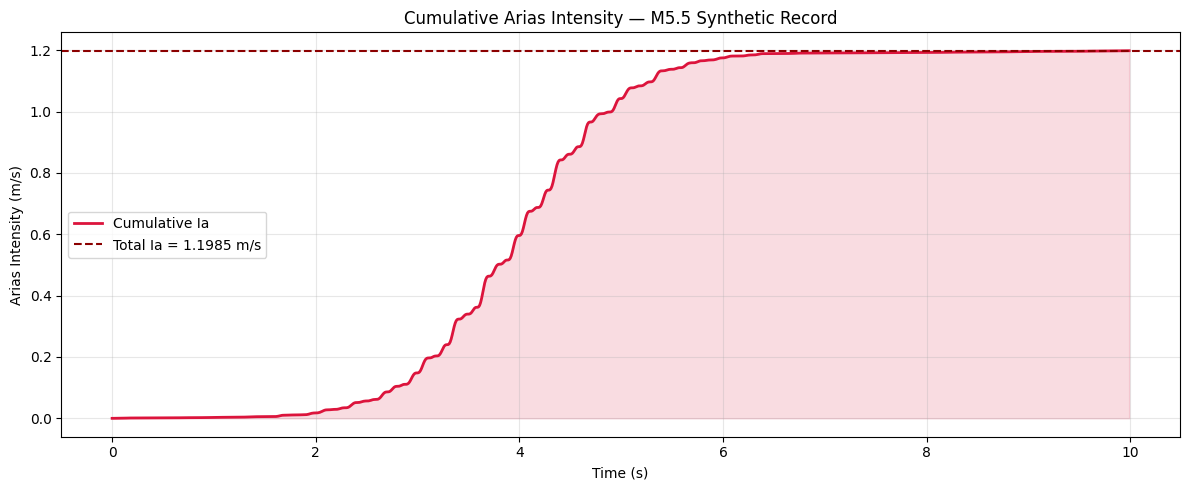

In [9]:
# ─────────────────────────────────────────────────────
# ARIAS INTENSITY — Ia = π/(2g) ∫ a²(t) dt
# Convert acceleration from g to m/s² first
# ─────────────────────────────────────────────────────

g       = 9.81                    # m/s²
dt      = 1.0 / fs                # time step (s)

# Use the low-pass filtered signal (standard practice: filter first)
a_ms2   = a_lp_filtered * g      # convert g → m/s²

# Trapezoidal integration of a²(t)
a2_dt   = a_ms2**2 * dt          # incremental a²·dt
Ia_cum  = np.cumsum(a2_dt) * (np.pi / (2 * g))   # cumulative Arias Intensity (m/s)
Ia_total = Ia_cum[-1]

print(f'Total Arias Intensity Ia : {Ia_total:.4f} m/s')
print(f'                         : {Ia_total*100:.2f} cm/s')

# Threshold levels
Ia_thresholds = {'Low damage (Ia<0.05m/s)': 0.05, 'Moderate (Ia=0.5m/s)': 0.5}
for label, thresh in Ia_thresholds.items():
    status = 'EXCEEDS' if Ia_total > thresh else 'below'
    print(f'  {label}: {status}')

plt.figure(figsize=(12, 5))
plt.plot(t, Ia_cum, color='crimson', lw=2, label='Cumulative Ia')
plt.axhline(Ia_total, color='darkred', ls='--', lw=1.5,
            label=f'Total Ia = {Ia_total:.4f} m/s')
plt.fill_between(t, Ia_cum, alpha=0.15, color='crimson')
plt.xlabel('Time (s)')
plt.ylabel('Arias Intensity (m/s)')
plt.title('Cumulative Arias Intensity — M5.5 Synthetic Record')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Part 9: Significant Duration D5-95

t5   (5%  Ia) : 2.560 s
t75  (75% Ia) : 4.630 s
t95  (95% Ia) : 5.530 s
D5-75         : 2.070 s
D5-95         : 2.970 s  ← significant duration


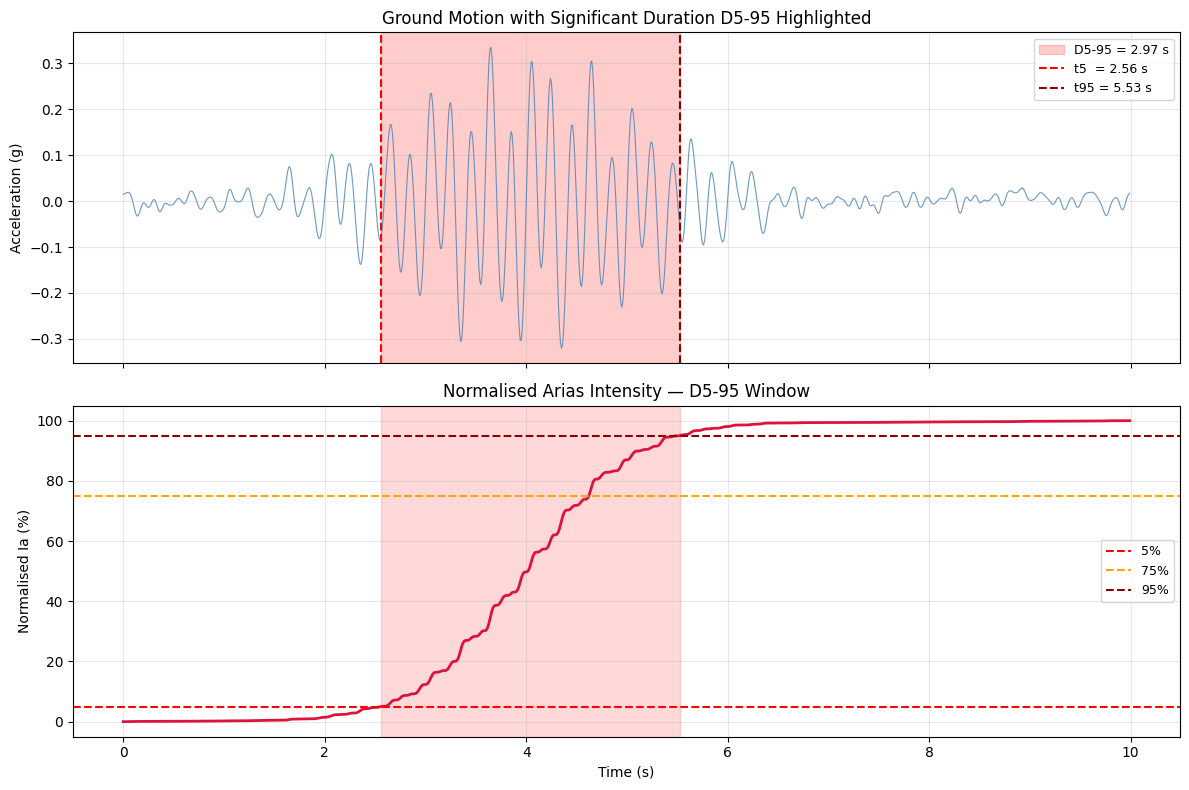

In [10]:
# ─────────────────────────────────────────────────────
# D5-95: time between 5% and 95% of total Arias Intensity
# Standard duration metric for ground motion selection
# and non-linear site response analysis
# ─────────────────────────────────────────────────────

Ia_norm = Ia_cum / Ia_total    # normalise to 0–1

# Find time indices where normalised Ia crosses 5% and 95%
idx_5  = np.searchsorted(Ia_norm, 0.05)
idx_95 = np.searchsorted(Ia_norm, 0.95)

t_5  = t[idx_5]
t_95 = t[idx_95]
D5_95 = t_95 - t_5

# Also compute D5-75 (sometimes used for soil response)
idx_75 = np.searchsorted(Ia_norm, 0.75)
t_75   = t[idx_75]
D5_75  = t_75 - t_5

print(f't5   (5%  Ia) : {t_5:.3f} s')
print(f't75  (75% Ia) : {t_75:.3f} s')
print(f't95  (95% Ia) : {t_95:.3f} s')
print(f'D5-75         : {D5_75:.3f} s')
print(f'D5-95         : {D5_95:.3f} s  ← significant duration')

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(t, a_lp_filtered, lw=0.8, color='steelblue', alpha=0.8)
axes[0].axvspan(t_5, t_95, alpha=0.2, color='red', label=f'D5-95 = {D5_95:.2f} s')
axes[0].axvline(t_5,  color='red',  ls='--', lw=1.5, label=f't5  = {t_5:.2f} s')
axes[0].axvline(t_95, color='darkred', ls='--', lw=1.5, label=f't95 = {t_95:.2f} s')
axes[0].set_ylabel('Acceleration (g)')
axes[0].set_title('Ground Motion with Significant Duration D5-95 Highlighted')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

axes[1].plot(t, Ia_norm * 100, color='crimson', lw=2)
axes[1].axhline(5,  color='red',     ls='--', lw=1.5, label='5%')
axes[1].axhline(75, color='orange',  ls='--', lw=1.5, label='75%')
axes[1].axhline(95, color='darkred', ls='--', lw=1.5, label='95%')
axes[1].axvspan(t_5, t_95, alpha=0.15, color='red')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Normalised Ia (%)')
axes[1].set_title('Normalised Arias Intensity — D5-95 Window')
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Part 10: Complete Processing Pipeline

In [11]:
# ═══════════════════════════════════════════════════════
# FULL EARTHQUAKE RECORD PROCESSING PIPELINE
# Steps: filter → FFT → Welch → peaks → Ia → D5-95
# ═══════════════════════════════════════════════════════

def process_ground_motion(accel_g, fs, fc_lp=10.0, fc_band=(1.0, 8.0)):
    """
    Full processing pipeline for a ground acceleration record.
    
    Parameters
    ----------
    accel_g : array  Raw acceleration in g
    fs      : float  Sampling rate (Hz)
    fc_lp   : float  Low-pass corner (Hz)
    fc_band : tuple  Band-pass corners (Hz)
    
    Returns
    -------
    dict with all intensity measures
    """
    g_const = 9.81
    N_s = len(accel_g)
    dt  = 1.0 / fs

    # 1. Low-pass filter
    b, a = butter(4, fc_lp, btype='low', fs=fs)
    a_filt = filtfilt(b, a, accel_g)

    # 2. Band-pass filter
    b2, a2 = butter(4, list(fc_band), btype='band', fs=fs)
    a_bp   = filtfilt(b2, a2, accel_g)

    # 3. FFT
    A      = fft.fft(a_filt)
    freqs  = np.fft.fftfreq(N_s, d=dt)
    pos    = freqs >= 0
    amp    = (2 / N_s) * np.abs(A[pos])
    freqs_p = freqs[pos]
    f_dom_fft = freqs_p[np.argmax(amp)]

    # 4. Welch PSD
    fw, psd = welch(a_filt, fs=fs, nperseg=256, noverlap=128)
    f_dom_welch = fw[np.argmax(psd)]

    # 5. Intensity measures
    PGA  = np.max(np.abs(a_filt))
    RMS  = np.sqrt(np.mean(a_filt**2))
    a_ms2 = a_filt * g_const
    Ia_cum = np.cumsum(a_ms2**2 * dt) * (np.pi / (2 * g_const))
    Ia_total = Ia_cum[-1]

    # 6. D5-95
    t_arr  = np.arange(N_s) * dt
    norm   = Ia_cum / Ia_total
    t_5    = t_arr[np.searchsorted(norm, 0.05)]
    t_95   = t_arr[np.searchsorted(norm, 0.95)]
    D5_95  = t_95 - t_5

    return {
        'PGA_g'          : PGA,
        'PGA_cms2'       : PGA * g_const * 100,
        'RMS_accel_g'    : RMS,
        'Ia_m_s'         : Ia_total,
        'D5_95_s'        : D5_95,
        't5_s'           : t_5,
        't95_s'          : t_95,
        'f_dom_FFT_Hz'   : f_dom_fft,
        'Ts_FFT_s'       : 1.0 / f_dom_fft if f_dom_fft > 0 else np.nan,
        'f_dom_Welch_Hz' : f_dom_welch,
        'Ts_Welch_s'     : 1.0 / f_dom_welch if f_dom_welch > 0 else np.nan,
    }


results = process_ground_motion(a_raw, fs)

print('=' * 55)
print(' GROUND MOTION INTENSITY MEASURE REPORT ')
print('=' * 55)
print(f" Site            : BH-Site, M5.5 Synthetic Record")
print(f" Sampling rate   : {fs} Hz  |  Duration: {T} s")
print('-' * 55)
print(f" PGA             : {results['PGA_g']:.4f} g  ({results['PGA_cms2']:.1f} cm/s²)")
print(f" RMS Accel.      : {results['RMS_accel_g']:.4f} g")
print(f" Arias Intensity : {results['Ia_m_s']:.4f} m/s")
print(f" D5-95 duration  : {results['D5_95_s']:.3f} s  (t5={results['t5_s']:.2f}s → t95={results['t95_s']:.2f}s)")
print(f" Dominant f (FFT): {results['f_dom_FFT_Hz']:.2f} Hz  →  Ts = {results['Ts_FFT_s']:.3f} s")
print(f" Dominant f (Wlch): {results['f_dom_Welch_Hz']:.2f} Hz  →  Ts = {results['Ts_Welch_s']:.3f} s")
print('=' * 55)

# Liquefaction screening (Travasarou et al., 2003: Ia > 0.021 m/s for triggering)
liq_thresh = 0.021
liq_flag   = 'POTENTIAL LIQUEFACTION TRIGGERING' if results['Ia_m_s'] > liq_thresh else 'Below triggering threshold'
print(f" Liquefaction IMs: {liq_flag} (Ia threshold = {liq_thresh} m/s)")
print('=' * 55)

 GROUND MOTION INTENSITY MEASURE REPORT 
 Site            : BH-Site, M5.5 Synthetic Record
 Sampling rate   : 100 Hz  |  Duration: 10.0 s
-------------------------------------------------------
 PGA             : 0.3349 g  (328.5 cm/s²)
 RMS Accel.      : 0.0882 g
 Arias Intensity : 1.1985 m/s
 D5-95 duration  : 2.970 s  (t5=2.56s → t95=5.53s)
 Dominant f (FFT): 5.00 Hz  →  Ts = 0.200 s
 Dominant f (Wlch): 5.08 Hz  →  Ts = 0.197 s
 Liquefaction IMs: POTENTIAL LIQUEFACTION TRIGGERING (Ia threshold = 0.021 m/s)


## Practice Exercises

### Exercise 1
Change the band-pass filter to 0.5–3 Hz to isolate only long-period content. Compare the PGA and Arias Intensity of this signal to the 1–8 Hz band-pass version.

### Exercise 2
Add a fourth sinusoid at 0.5 Hz (long-period baseline drift) with amplitude 0.02 g. Apply a high-pass filter at 0.1 Hz to remove it and verify it is gone in the FFT.

### Exercise 3
Use `scipy.signal.sosfilt` (second-order sections) instead of `butter + filtfilt` for better numerical stability with higher-order filters. Compare results for order=8.

```python
# Exercise 1 starter
# b_ex, a_ex = butter(4, [0.5, 3.0], btype='band', fs=fs)
# a_ex_filt  = filtfilt(b_ex, a_ex, a_raw)
# ...

# Exercise 2 starter
# a_drift = a_raw + 0.02 * np.sin(2 * np.pi * 0.5 * t)
# b_hp, a_hp = butter(4, 0.1, btype='high', fs=fs)
# a_hp_filt  = filtfilt(b_hp, a_hp, a_drift)
# ...

# Exercise 3 starter
# from scipy.signal import sosfilt, sosfiltfilt
# sos = butter(8, fc_lp, btype='low', fs=fs, output='sos')
# a_sos = sosfiltfilt(sos, a_raw)
# ...
```

---

## Key Takeaways

1. **`butter + filtfilt`**: always use `filtfilt` (not `lfilter`) for geotechnical signals — zero-phase avoids artificial time shifts that corrupt Arias Intensity calculations.
2. **FFT vs Welch**: raw FFT is noisy (variance ∝ amplitude²). Welch averages overlapping periodograms — use it for site characterisation and dominant period identification.
3. **`find_peaks`**: powerful for automated spectral peak picking; tune `height`, `distance`, and `prominence` to avoid false detections in noisy PSD.
4. **Spectrogram**: reveals non-stationarity — essential for earthquake records where energy content changes from P-wave arrival through S-wave and surface waves.
5. **Arias Intensity + D5-95**: the two most important ground motion intensity measures for geotechnical hazard assessment; always compute from the filtered (not raw) record.

## How This Connects to ML

| Today | In ML (Phase 3–5) |
|-------|-------------------|
| FFT amplitude spectrum | Feature vector for ground motion classification |
| Welch PSD | Input features for site amplification regression |
| Spectrogram | 2D image input for CNN-based seismic phase picking |
| Arias Intensity, D5-95 | Target labels / input features for liquefaction ML |
| Dominant frequency peaks | Categorical features for site class prediction |

---

*Day 029 of 100 — Your signals are clean, your frequencies are known. The ground shakes, but the data is solid!*